# Random Forest for predicting reading comprehension based on eye-gaze
**Regression** ·  one row per child · target: `score_global` (% correct, 0–100)

Workflow: data → Random Forest → results → variable importance → comparison with other models.

## 0. Configuration

In [17]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RepeatedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
DATA = "dataset_participantes.csv"
SEED = 42
FIG = Path("figuras"); FIG.mkdir(exist_ok=True) 

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 11})
AZUL, OSCURO, GRIS, ROJO = "#2E6DB4", "#0E1E3E", "#9AA5B1", "#D1495B"

## 1. Data
One row per child. We keep the children who have a score **and** gaze data.

In [18]:
df = pd.read_csv(DATA)
print("Participants:", len(df))

df["sync_estimada"] = (df["sincronizacion"] == "ESTIMADO").astype(int)
VEL    = ["wpm_general"]
MIRADA = ["fijaciones_por_s", "pct_tiempo_sacada", "sac_amp_mediana_deg", "fix_dur_media_ms",
          "fijaciones_por_s_idt", "pct_tiempo_no_fijo_idt", "kappa_ivt_idt", "sync_estimada"]
TARGET = "score_global"

d = df.dropna(subset=[TARGET] + VEL + MIRADA).reset_index(drop=True)
print("Participants:", len(d), "| gaze:", len(MIRADA), "| + reading vel:", len(VEL))
X, y = d[VEL + MIRADA], d[TARGET]
d[[TARGET] + VEL + MIRADA].describe().T[["count", "mean", "std", "min", "max"]].round(2)

Participants: 104
Participants: 98 | gaze: 8 | + reading vel: 1


,count,mean,std,min,max
score_global,98.0,72.62,27.81,0.00,100.00
wpm_general,98.0,88.31,28.68,25.50,148.30
fijaciones_por_s,98.0,1.69,0.17,1.21,1.98
pct_tiempo_sacada,98.0,15.40,2.30,11.60,24.05
sac_amp_mediana_deg,98.0,2.25,0.80,0.84,6.27
fix_dur_media_ms,98.0,498.69,50.17,419.97,701.27
fijaciones_por_s_idt,98.0,1.44,0.12,0.69,1.69
pct_tiempo_no_fijo_idt,98.0,18.46,3.10,9.00,28.50
kappa_ivt_idt,98.0,0.53,0.08,0.37,0.72
sync_estimada,98.0,0.26,0.44,0.00,1.00


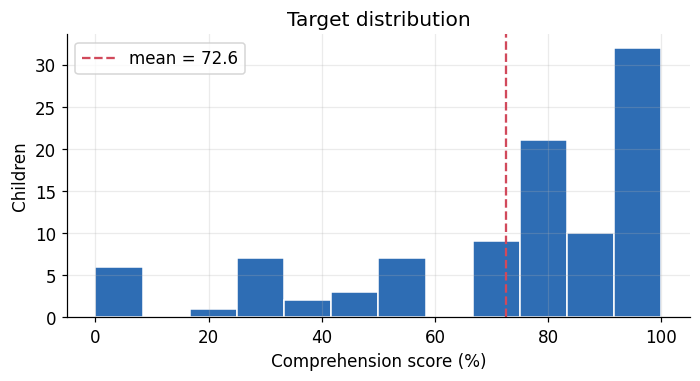

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(y, bins=12, color=AZUL, edgecolor="white")
ax.axvline(y.mean(), color=ROJO, ls="--", label=f"mean = {y.mean():.1f}")
ax.set(xlabel="Comprehension score (%)", ylabel="Children", title="Target distribution"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "01_distribucion_score.png", dpi=200); plt.show()

## 2. Random Forest
80/20 split per child.
Compared against the **baseline**: always predicting the mean.

In [20]:
def metricas(y_real, y_pred):
    sse = float(((y_real - y_pred) ** 2).sum())
    mse = mean_squared_error(y_real, y_pred)
    return {"SSE": sse, "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_real, y_pred), "R2": r2_score(y_real, y_pred)}

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train: {len(Xtr)} | Test: {len(Xte)}")

t0 = time.time()
rf = RandomForestRegressor(n_estimators=500, max_features=1/3, min_samples_leaf=3,
                           oob_score=True, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
print(f"Training time {time.time() - t0:.1f} s")

base = DummyRegressor().fit(Xtr, ytr)
pd.DataFrame({"Baseline (media)": metricas(yte, base.predict(Xte)),
              "Random Forest":    metricas(yte, rf.predict(Xte))}).T.round(2)

Train: 78 | Test: 20
Training time 0.5 s


,SSE,MSE,RMSE,MAE,R2
Baseline (media),12406.59,620.33,24.91,19.48,-0.03
Random Forest,7639.73,381.99,19.54,15.83,0.37


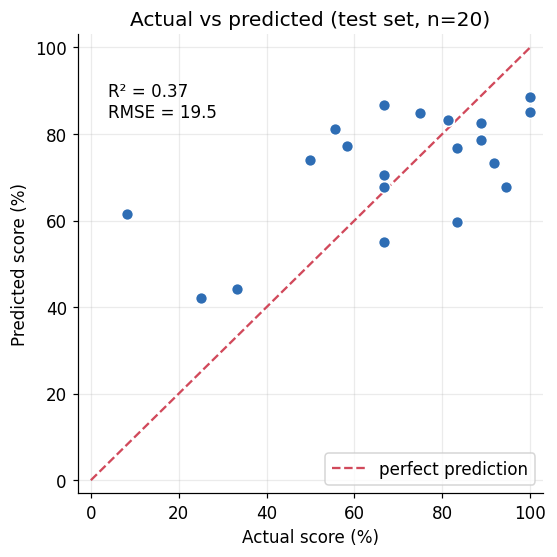

In [21]:
pred = rf.predict(Xte)
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(yte, pred, s=60, color=AZUL, edgecolor="white", zorder=3)
ax.plot([0, 100], [0, 100], color=ROJO, ls="--", label="perfect prediction")
ax.set(xlim=(-3, 103), ylim=(-3, 103), xlabel="Actual score (%)", ylabel="Predicted score (%)",
       title=f"Actual vs predicted (test set, n={len(yte)})")
ax.text(4, 92, f"R² = {r2_score(yte, pred):.2f}\nRMSE = {np.sqrt(mean_squared_error(yte, pred)):.1f}", va="top")
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(FIG / "02_real_vs_predicho.png", dpi=200); plt.show()

## 3. How many trees are needed?
Each tree is trained using a bootstrap sample; the instances that were not included (out-of-bag, or OOB) are used for evaluation, without touching the test set.

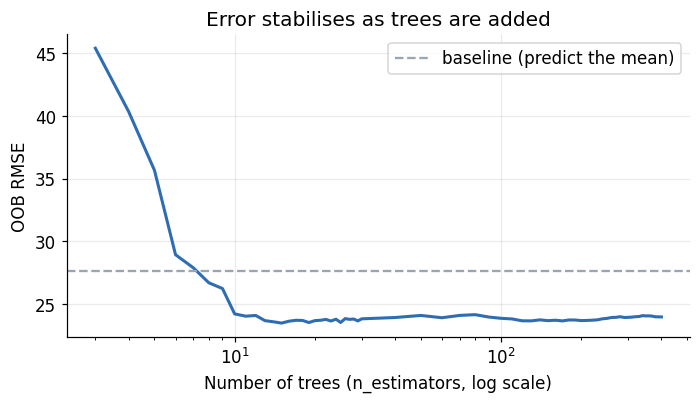

RMSE OOB with 3 tree: 45.40 | with 30: 23.81 | with 400: 23.97


In [22]:
def oob_rmse(model, y):
    p = model.oob_prediction_
    ok = ~np.isnan(p)
    return np.sqrt(np.mean((y[ok] - p[ok]) ** 2))

arboles = list(range(3, 31, 1)) + list(range(40, 401, 10))
m = RandomForestRegressor(max_features=1/3, min_samples_leaf=3, oob_score=True,
                          warm_start=True, random_state=SEED, n_jobs=-1)
curva = []
for n in arboles:
    m.set_params(n_estimators=n).fit(X, y)
    curva.append(oob_rmse(m, y.values))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(arboles, curva, color=AZUL, lw=2)
ax.axhline(y.std(ddof=0), color=GRIS, ls="--", label="baseline (predict the mean)")
ax.set(xscale="log", xlabel="Number of trees (n_estimators, log scale)", ylabel="OOB RMSE", title="Error stabilises as trees are added"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "03_curva_oob.png", dpi=200); plt.show()
print(f"RMSE OOB with {arboles[0]} tree: {curva[0]:.2f} | with 30: {curva[arboles.index(30)]:.2f} | with 400: {curva[-1]:.2f}")

## 4. Comparison with other models
**5×5** cross-validation (5 partitions, repeated 5 times) using the same partitions for all models.
Metrics are calculated based on all out-of-sample predictions and averaged across repetitions.
Hyperparameters are fixed so that no model has an advantage.

In [23]:
def modelos():
    return {
     "Baseline (mean)":  DummyRegressor(),
     "Decision Tree":    DecisionTreeRegressor(max_depth=4, random_state=SEED),
     "Ridge":            make_pipeline(StandardScaler(), Ridge(alpha=10)),
     "SVR":              make_pipeline(StandardScaler(), SVR(C=50, epsilon=5)),
     "Gradient Boosting":GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                   subsample=0.8, random_state=SEED),
     "Random Forest":    RandomForestRegressor(n_estimators=300, max_features=1/3, min_samples_leaf=3,
                                               random_state=SEED, n_jobs=-1),
    }

REPS, K = 5, 5
def cv_repetida(modelo, X, y, reps=REPS, k=K):
    Xv, yv = X.values, y.values
    filas, primera = [], None
    for r in range(reps):
        pred = np.zeros(len(yv))
        for itr, ite in RepeatedKFold(n_splits=k, n_repeats=1, random_state=r).split(Xv):
            pred[ite] = clone(modelo).fit(Xv[itr], yv[itr]).predict(Xv[ite])
        filas.append(metricas(yv, pred))
        if r == 0: primera = pred
    df_ = pd.DataFrame(filas)
    out = df_.mean().to_dict(); out["R2_sd"] = df_["R2"].std()
    return out, primera

t0 = time.time()
res, preds = {}, {}
for nombre, mod in modelos().items():
    res[nombre], preds[nombre] = cv_repetida(mod, X, y)
tabla = pd.DataFrame(res).T[["SSE", "MSE", "RMSE", "MAE", "R2", "R2_sd"]]

def resaltar(s):
    mejor = s.max() if s.name in ("R2",) else s.min()
    return ["font-weight:bold; background-color:#cfe3f7" if v == mejor else "" for v in s]
tabla.round(2).style.apply(resaltar, subset=["SSE", "MSE", "RMSE", "MAE", "R2"]).format("{:,.2f}")

,SSE,MSE,RMSE,MAE,R2,R2_sd
Baseline (mean),"76,299.78",778.57,27.90,22.39,-0.02,0.01
Decision Tree,"71,951.80",734.20,27.08,20.49,0.04,0.06
Ridge,"62,479.00",637.54,25.23,20.55,0.17,0.06
SVR,"68,955.22",703.62,26.52,20.84,0.08,0.05
Gradient Boosting,"61,867.01",631.30,25.12,19.76,0.18,0.04
Random Forest,"59,271.43",604.81,24.59,20.32,0.21,0.03


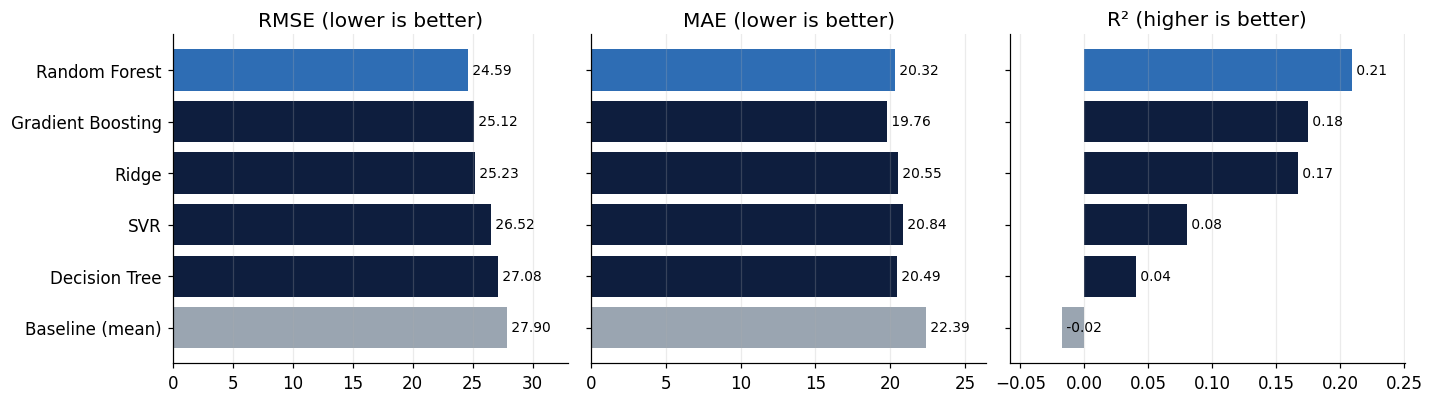

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
orden = tabla.sort_values("RMSE", ascending=False).index
for ax, (met, titulo) in zip(axes, [("RMSE", "RMSE (lower is better)"), ("MAE", "MAE (lower is better)"), ("R2", "R² (higher is better)")]):
    cols = [AZUL if n == "Random Forest" else (GRIS if "Baseline" in n else OSCURO) for n in orden]
    ax.barh(orden, tabla.loc[orden, met], color=cols)
    ax.set_title(titulo)
    for i, n in enumerate(orden):
        ax.text(tabla.loc[n, met], i, f" {tabla.loc[n, met]:.2f}", va="center", fontsize=9)
    ax.margins(x=.18); ax.grid(axis="y", alpha=0)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
fig.tight_layout(); fig.savefig(FIG / "04_comparacion_modelos.png", dpi=200); plt.show()
tabla.round(2).to_csv(FIG / "tabla_comparacion_modelos.csv")

### Where does the signal come from? Same Random Forest, different sets of variables.
This is the central question of the project: does **gaze** predict performance, or is it only **reading speed** that does so?

In [25]:
rf_cv = modelos()["Random Forest"]
conjuntos = {"Gaze only": MIRADA, "Reading speed only": VEL, "Reading speed + gaze": VEL + MIRADA}
filas = {}
for nombre, cols in conjuntos.items():
    filas[nombre], _ = cv_repetida(rf_cv, d[cols], y)
ablacion = pd.DataFrame(filas).T[["SSE", "MSE", "RMSE", "MAE", "R2", "R2_sd"]]
display(ablacion.round(2))
print(f"Baseline (media): RMSE {tabla.loc['Baseline (mean)','RMSE']:.2f} | R² {tabla.loc['Baseline (mean)','R2']:.2f}")

,SSE,MSE,RMSE,MAE,R2,R2_sd
Gaze only,74187.02,757.01,27.51,22.55,0.01,0.04
Reading speed only,61789.73,630.51,25.10,20.09,0.18,0.04
Reading speed + gaze,59271.43,604.81,24.59,20.32,0.21,0.03


Baseline (media): RMSE 27.90 | R² -0.02


## 5. Which variables matter?
One variable at a time is shuffled within the **test** data, and the resulting increase in error is measured. This is averaged across all cross-validation (CV) folds, making it more stable than using a single partition.

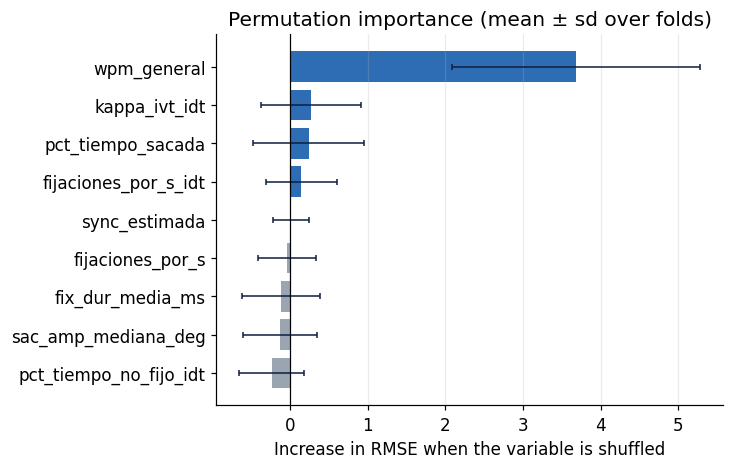

(13 s)


In [26]:
t0 = time.time()
imp = []
Xv, yv = X.values, y.values
for r in range(3):
    for itr, ite in RepeatedKFold(n_splits=5, n_repeats=1, random_state=r).split(Xv):
        mod = clone(modelos()["Random Forest"]).set_params(n_jobs=1).fit(Xv[itr], yv[itr])
        pi = permutation_importance(mod, Xv[ite], yv[ite], scoring="neg_root_mean_squared_error",
                                    n_repeats=10, random_state=SEED)
        imp.append(pi.importances_mean)
imp = pd.DataFrame(imp, columns=X.columns)
media, sd = imp.mean(), imp.std()
orden = media.sort_values()

fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.barh(orden.index, orden.values, xerr=sd[orden.index].values, color=[AZUL if v > 0 else GRIS for v in orden.values],
        error_kw=dict(ecolor=OSCURO, lw=1, capsize=2))
ax.axvline(0, color="k", lw=.8)
ax.set(xlabel="Increase in RMSE when the variable is shuffled", title="Permutation importance (mean ± sd over folds)")
ax.grid(axis="y", alpha=0); fig.tight_layout(); fig.savefig(FIG / "05_importancia_permutacion.png", dpi=200); plt.show()
print(f"({time.time() - t0:.0f} s)")

## 6. Sensitivity to hyperparameters
Small grid search over `max_features` and `min_samples_leaf`.

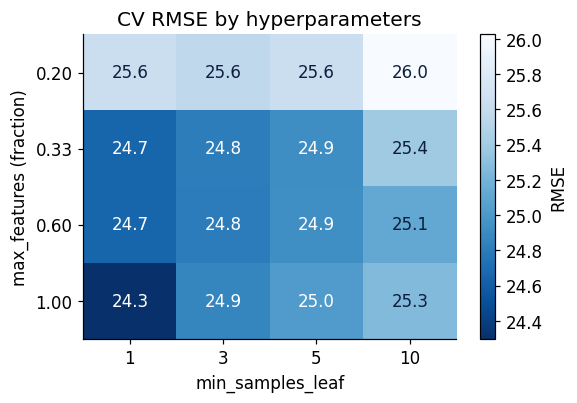

In [27]:
mf = [0.2, 1/3, 0.6, 1.0]; ml = [1, 3, 5, 10]
grid = pd.DataFrame(index=[f"{v:.2f}" for v in mf], columns=ml, dtype=float)
for a in mf:
    for b in ml:
        mod = RandomForestRegressor(n_estimators=100, max_features=a, min_samples_leaf=b, random_state=SEED, n_jobs=1)
        grid.loc[f"{a:.2f}", b] = cv_repetida(mod, X, y, reps=2)[0]["RMSE"]

fig, ax = plt.subplots(figsize=(5.4, 3.8))
im = ax.imshow(grid.values.astype(float), cmap="Blues_r", aspect="auto")
ax.set_xticks(range(len(ml)), ml); ax.set_yticks(range(len(mf)), grid.index)
ax.set(xlabel="min_samples_leaf", ylabel="max_features (fraction)", title="CV RMSE by hyperparameters"); ax.grid(False)
for i in range(len(mf)):
    for j in range(len(ml)):
        ax.text(j, i, f"{grid.values[i, j]:.1f}", ha="center", va="center", color="w" if grid.values[i, j] < np.nanmean(grid.values.astype(float)) else OSCURO)
fig.colorbar(im, label="RMSE"); fig.tight_layout(); fig.savefig(FIG / "06_hiperparametros.png", dpi=200); plt.show()